## Parcial Práctico - Colas de prioridad y Árbol de Expansión Mínima

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.


In [23]:

nombre_estudiante = "Laura Juliana Ceron Acosta"
carnet = 1000116542


## 1) Descripción del problema **[1 pts]**

Una empresa administra tareas técnicas mediante una **cola de prioridad máxima** implementada con un **Max-Heap**, procesando siempre primero la tarea más urgente. Además, debe conectar seis dispositivos con la menor cantidad total de cable posible, lo cual se resuelve construyendo un **Árbol de Expansión Mínima (MST)** con el algoritmo de **Kruskal**, usando la distancia euclidiana entre dispositivos como peso de cada posible conexión.

## 2) Requerimientos **[2 pts]**

**Funcionales:**
- Construir un Max-Heap a partir del arreglo inicial de tareas (`BUILD-MAX-HEAP`).
- Extraer la tarea de mayor prioridad manteniendo la propiedad del heap (`EXTRACT-MAX`).
- Insertar una nueva tarea conservando la propiedad del heap (`MAX-HEAP-INSERT` / `HEAP-INCREASE-KEY`).
- Calcular la distancia euclidiana entre cada par de dispositivos.
- Construir el MST con Kruskal, evitando ciclos mediante conjuntos disjuntos (Union-Find).
- Visualizar gráficamente los dispositivos y el MST final con sus pesos.

**No funcionales:**
- No usar `heapq` ni funciones de librerías que calculen el MST directamente.
- `MAX-HEAPIFY` en O(log n), `BUILD-MAX-HEAP` en O(n).
- Kruskal en O(E log E), con Union-Find casi O(1) amortizado por operación.

## 3) Historias de usuario **[2 pts]**

**HU1.** *Como* coordinador técnico, *quiero* que siempre se procese primero la tarea de mayor prioridad, *para* atender primero lo más urgente.
- *Criterio de aceptación:* `EXTRACT-MAX` siempre retorna la tarea con prioridad más alta disponible en el heap.

**HU2.** *Como* coordinador, *quiero* poder agregar tareas nuevas en cualquier momento, *para* reaccionar a imprevistos sin reconstruir todo el sistema.
- *Criterio de aceptación:* tras insertar una tarea, el heap sigue cumpliendo la propiedad Max-Heap.

**HU3.** *Como* ingeniero de infraestructura, *quiero* conectar todos los dispositivos con la menor cantidad de cable, *para* minimizar costos de instalación.
- *Criterio de aceptación:* el conjunto de conexiones seleccionado conecta los 6 dispositivos sin ciclos y con el menor costo total posible.

**HU4.** *Como* supervisor, *quiero* ver gráficamente la distribución de dispositivos y las conexiones elegidas, *para* validar visualmente que la solución es razonable.
- *Criterio de aceptación:* la gráfica final muestra los 6 dispositivos, solo las aristas del MST y su peso.

## 4) Diagramas de flujo **[5 pts]**


**Diagrama 1 — BUILD-MAX-HEAP / MAX-HEAPIFY:**

![Diagrama de flujo 1.png](<attachment:Diagrama de flujo 1.png>)
```

**Diagrama 2 — Kruskal (MST):**
```
![Diagrama De flujo 2.png](<attachment:Diagrama De flujo 2.png>)
```
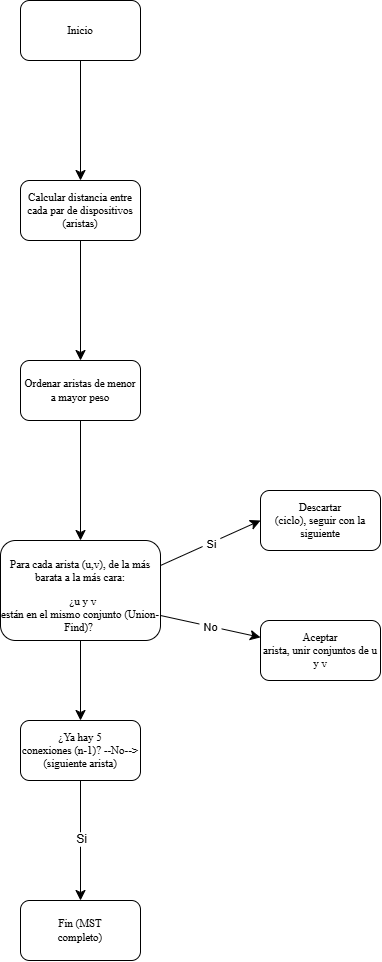
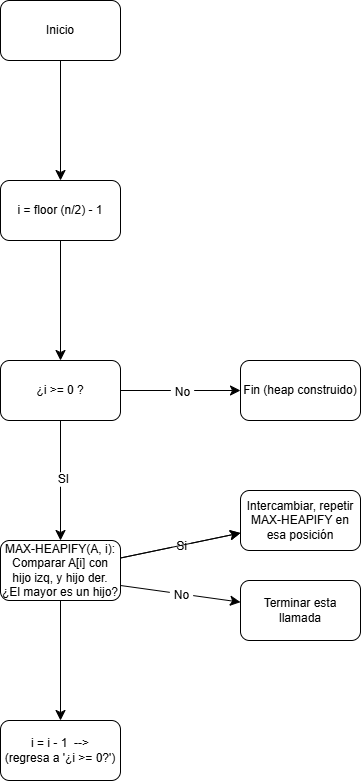

### 5) Análisis de complejidad **[15 pts]**

**Justificación:**

- `MAX-HEAPIFY` desciende como máximo la altura del heap (h = log n) → O(log n).
- `BUILD-MAX-HEAP` llama a `MAX-HEAPIFY` desde n/2 nodos, pero el análisis amortizado (no n·log n ingenuo) da **O(n)** porque la mayoría de los nodos están cerca de las hojas y heapifican poco.
- `EXTRACT-MAX` y `MAX-HEAP-INSERT` hacen trabajo O(1) más una llamada a `MAX-HEAPIFY`/burbujeo → O(log n).
- Kruskal: ordenar E aristas cuesta O(E log E); procesar cada arista con Union-Find (con compresión de caminos) cuesta casi O(1) amortizado → total **O(E log E)**.

**Función T(n):**

Heap (n tareas): T(n) = O(n) [construcción] + k·O(log n) [k operaciones de extracción/inserción]

Kruskal (V vértices, E aristas, grafo completo E=V(V-1)/2): T(V) = O(E log E) = O(V² log V)

**Mejor caso:** el heap ya cumple la propiedad al construirse (arreglo ya en orden de max-heap) → `MAX-HEAPIFY` no intercambia nada, O(1) por llamada. En Kruskal, si las primeras V-1 aristas más baratas ya forman un árbol sin ciclos, se detiene apenas se revisan V-1 aristas.

**Peor caso:** cada inserción/heapify baja hasta una hoja → O(log n). En Kruskal, hay que revisar casi todas las E aristas antes de completar las V-1 conexiones (muchos descartes por ciclo) → se acerca a O(E log E).

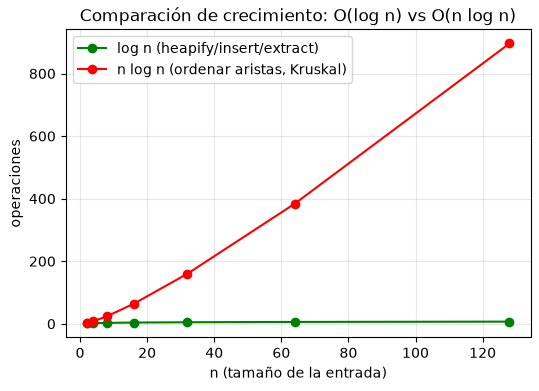

## 6) Código funcional **[15 pts]**

In [37]:
import math
import matplotlib.pyplot as plt


def izq(i): return 2 * i + 1
def der(i): return 2 * i + 2
def padre(i): return (i - 1) // 2


def max_heapify(A, i, heap_size):
    l, r = izq(i), der(i)
    mayor = i
    if l < heap_size and A[l][2] > A[mayor][2]:
        mayor = l
    if r < heap_size and A[r][2] > A[mayor][2]:
        mayor = r
    if mayor != i:
        A[i], A[mayor] = A[mayor], A[i]
        max_heapify(A, mayor, heap_size)


def build_max_heap(A):
    n = len(A)
    for i in range(n // 2 - 1, -1, -1):
        max_heapify(A, i, n)


def extract_max(A, heap_size):
    maximo = A[0]
    A[0] = A[heap_size - 1]
    heap_size -= 1
    max_heapify(A, 0, heap_size)
    return maximo, heap_size


def heap_increase_key(A, i, nueva_tarea):
    A[i] = nueva_tarea
    while i > 0 and A[padre(i)][2] < A[i][2]:
        A[i], A[padre(i)] = A[padre(i)], A[i]
        i = padre(i)


def max_heap_insert(A, heap_size, tarea):
    A.append(None)
    heap_size += 1
    heap_increase_key(A, heap_size - 1, tarea)
    return heap_size


def dibujar_heap(A, heap_size, titulo):
    fig, ax = plt.subplots(figsize=(7, 4))
    niveles = {}
    for i in range(heap_size):
        nivel = i.bit_length() - 1
        niveles.setdefault(nivel, []).append(i)
    posiciones = {}
    for nivel, indices in niveles.items():
        ancho = len(indices)
        for pos, i in enumerate(indices):
            x = (pos + 1) / (ancho + 1)
            y = -nivel
            posiciones[i] = (x, y)
    for i in range(heap_size):
        for hijo in (izq(i), der(i)):
            if hijo < heap_size:
                x1, y1 = posiciones[i]
                x2, y2 = posiciones[hijo]
                ax.plot([x1, x2], [y1, y2], color='gray', zorder=1)
    for i in range(heap_size):
        x, y = posiciones[i]
        ax.scatter(x, y, s=1400, color='#cfe3ff', zorder=2, edgecolors='black')
        cod, _, prioridad = A[i]
        ax.text(x, y, f"{cod}\n{prioridad}", ha='center', va='center', fontsize=9, zorder=3)
    ax.set_title(titulo)
    ax.axis('off')
    plt.show()

### Punto 1 — Construcción del Max-Heap

Arreglo inicial:
[('T01', 6), ('T02', 10), ('T03', 4), ('T04', 8), ('T05', 3), ('T06', 7)]

Max-Heap resultante:
[('T02', 10), ('T04', 8), ('T06', 7), ('T01', 6), ('T05', 3), ('T03', 4)]


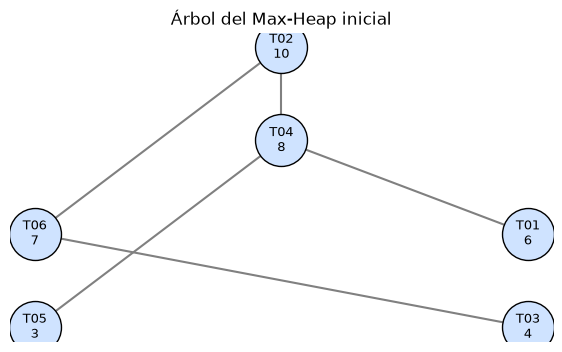

In [26]:
tareas = [
    ("T01", "Configurar servidor", 6),
    ("T02", "Reparar sensor", 10),
    ("T03", "Actualizar software", 4),
    ("T04", "Revisar cámara", 8),
    ("T05", "Generar respaldo", 3),
    ("T06", "Configurar alarma", 7),
]

A = list(tareas)
print("Arreglo inicial:")
print([(c, p) for c, _, p in A])

build_max_heap(A)
heap_size = len(A)
print("\nMax-Heap resultante:")
print([(c, p) for c, _, p in A])

dibujar_heap(A, heap_size, "Árbol del Max-Heap inicial")

### Punto 2 — Procesar tareas

Tarea procesada: T02 - Reparar sensor (prioridad 10)
Heap resultante: [('T04', 8), ('T01', 6), ('T06', 7), ('T03', 4), ('T05', 3)]


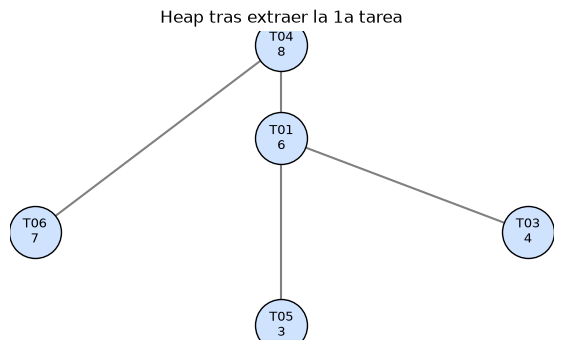

In [27]:
procesada_1, heap_size = extract_max(A, heap_size)
print(f"Tarea procesada: {procesada_1[0]} - {procesada_1[1]} (prioridad {procesada_1[2]})")
print("Heap resultante:", [(c, p) for c, _, p in A[:heap_size]])
dibujar_heap(A, heap_size, "Heap tras extraer la 1a tarea")

Tarea procesada: T04 - Revisar cámara (prioridad 8)
Heap resultante: [('T06', 7), ('T01', 6), ('T05', 3), ('T03', 4)]


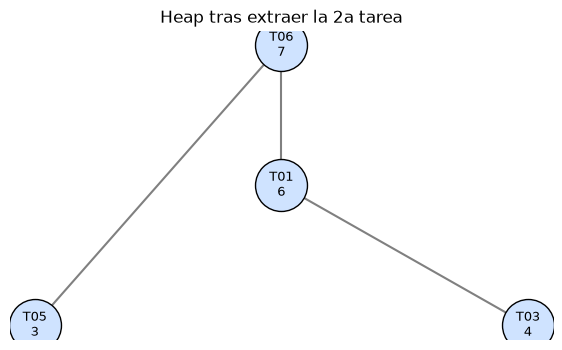

In [28]:
procesada_2, heap_size = extract_max(A, heap_size)
print(f"Tarea procesada: {procesada_2[0]} - {procesada_2[1]} (prioridad {procesada_2[2]})")
print("Heap resultante:", [(c, p) for c, _, p in A[:heap_size]])
dibujar_heap(A, heap_size, "Heap tras extraer la 2a tarea")

Heap tras insertar T07: [('T07', 12), ('T06', 7), ('T05', 3), ('T03', 4), ('T01', 6)]


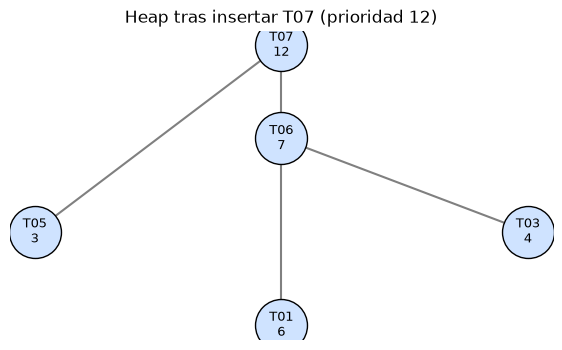

In [29]:
A = A[:heap_size]
nueva_tarea = ("T07", "Falla en sistema contra incendios", 12)
heap_size = max_heap_insert(A, heap_size, nueva_tarea)
print("Heap tras insertar T07:", [(c, p) for c, _, p in A[:heap_size]])
dibujar_heap(A, heap_size, "Heap tras insertar T07 (prioridad 12)")

### Punto 3 — Dispositivos y distancias

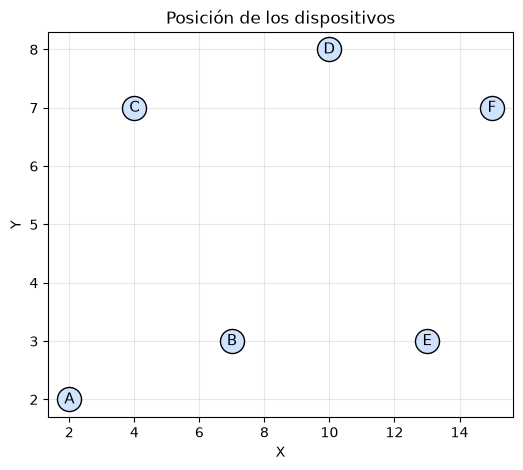

Distancias entre cada pareja de dispositivos:
E - F : 4.47
B - C : 5.00
A - B : 5.10
D - F : 5.10
A - C : 5.39
B - D : 5.83
D - E : 5.83
B - E : 6.00
C - D : 6.08
B - F : 8.94
C - E : 9.85
A - D : 10.00
C - F : 11.00
A - E : 11.05
A - F : 13.93


In [30]:
dispositivos = {
    "A": (2, 2),   # Servidor
    "B": (7, 3),   # Cámara
    "C": (4, 7),   # Sensor
    "D": (10, 8),  # Alarma
    "E": (13, 3),  # Router
    "F": (15, 7),  # Panel
}

fig, ax = plt.subplots(figsize=(6, 5))
for nombre, (x, y) in dispositivos.items():
    ax.scatter(x, y, s=300, color='#cfe3ff', edgecolors='black', zorder=2)
    ax.text(x, y, nombre, ha='center', va='center', fontsize=11, zorder=3)
ax.set_title("Posición de los dispositivos")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.grid(alpha=0.3)
plt.show()

def distancia(p1, p2):
    (x1, y1), (x2, y2) = p1, p2
    return math.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)

nombres = list(dispositivos.keys())
aristas = []
for i in range(len(nombres)):
    for j in range(i + 1, len(nombres)):
        u, v = nombres[i], nombres[j]
        d = distancia(dispositivos[u], dispositivos[v])
        aristas.append((d, u, v))
aristas.sort()

print("Distancias entre cada pareja de dispositivos:")
for d, u, v in aristas:
    print(f"{u} - {v} : {d:.2f}")

### Punto 4 — Árbol de Expansión Mínima (Kruskal)

In [ ]:
class ConjuntosDisjuntos:
    def __init__(self, elementos):
        self.padre = {e: e for e in elementos}
        self.tamano = {e: 1 for e in elementos}

    def encontrar(self, x):
        if self.padre[x] != x:
            self.padre[x] = self.encontrar(self.padre[x])
        return self.padre[x]

    def unir(self, x, y):
        raiz_x, raiz_y = self.encontrar(x), self.encontrar(y)
        if raiz_x == raiz_y:
            return False
        if self.tamano[raiz_x] < self.tamano[raiz_y]:
            raiz_x, raiz_y = raiz_y, raiz_x
        self.padre[raiz_y] = raiz_x
        self.tamano[raiz_x] += self.tamano[raiz_y]
        return True


def kruskal(nombres, aristas_ordenadas):
    conjuntos = ConjuntosDisjuntos(nombres)
    mst = []
    total = 0
    for peso, u, v in aristas_ordenadas:
        if conjuntos.unir(u, v):
            mst.append((u, v, peso))
            total += peso
        if len(mst) == len(nombres) - 1:
            break
    return mst, total


mst, longitud_total = kruskal(nombres, aristas)

print("Conexiones seleccionadas:")
for u, v, peso in mst:
    print(f"{u} - {v} : {peso:.2f}")
print(f"\nLongitud total de cable: {longitud_total:.2f}")

Conexiones seleccionadas:
E - F : 4.47
B - C : 5.00
A - B : 5.10
D - F : 5.10
B - D : 5.83

Longitud total de cable: 25.50


### Punto 5 — Visualización final del MST

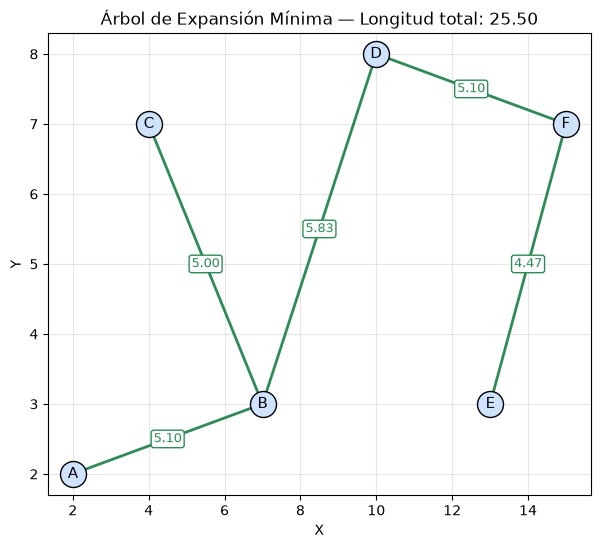

In [32]:
fig, ax = plt.subplots(figsize=(7, 6))
for nombre, (x, y) in dispositivos.items():
    ax.scatter(x, y, s=350, color='#cfe3ff', edgecolors='black', zorder=3)
    ax.text(x, y, nombre, ha='center', va='center', fontsize=11, zorder=4)

for u, v, peso in mst:
    x1, y1 = dispositivos[u]
    x2, y2 = dispositivos[v]
    ax.plot([x1, x2], [y1, y2], color='#2e8b57', linewidth=2, zorder=2)
    xm, ym = (x1 + x2) / 2, (y1 + y2) / 2
    ax.text(xm, ym, f"{peso:.2f}", color='#2e8b57', fontsize=9,
            ha='center', va='center',
            bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='#2e8b57'), zorder=5)

ax.set_title(f"Árbol de Expansión Mínima — Longitud total: {longitud_total:.2f}")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.grid(alpha=0.3)
plt.show()

## 7) Tests aplicados **[15 pts]**

In [33]:
def test(obtenido, esperado):
    assert obtenido == esperado, f"se obtuvo {obtenido}, se esperaba {esperado}"
    print(f"OK: {obtenido}")


# Punto 1
A_test = list(tareas)
build_max_heap(A_test)
test([c for c, _, _ in A_test], ["T02", "T04", "T06", "T01", "T05", "T03"])
test(A_test[0][2], 10)  # la raiz debe tener la prioridad maxima

# Propiedad de Max-Heap para cualquier heap construido
def es_max_heap(A, heap_size):
    for i in range(heap_size):
        for hijo in (izq(i), der(i)):
            if hijo < heap_size and A[hijo][2] > A[i][2]:
                return False
    return True

test(es_max_heap(A_test, len(A_test)), True)

# Punto 2
test(procesada_1[0], "T02")
test(procesada_2[0], "T04")
test(A[0][0], "T07")  # T07 (prioridad 12) debe quedar en la raiz

# Punto 4
test(len(mst), 5)
test(round(longitud_total, 2), 25.50)

# Conectividad: todos los dispositivos deben quedar unidos
conjuntos_check = ConjuntosDisjuntos(nombres)
for u, v, _ in mst:
    conjuntos_check.unir(u, v)
raices = {conjuntos_check.encontrar(n) for n in nombres}
test(len(raices), 1)

OK: ['T02', 'T04', 'T06', 'T01', 'T05', 'T03']
OK: 10
OK: True
OK: T02
OK: T04
OK: T07
OK: 5
OK: 25.5
OK: 1
